# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "Lanina"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [2]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

Saving weather_forecast.csv to weather_forecast.csv
Saving train.csv to train.csv
history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [3]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [4]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


# 1. EDA and visualisation

The goal of this section is to understand the main patterns in
electricity generation and identify the transformations and
seasonal components that may be useful for forecasting.

We investigate the time series, its daily seasonality,
and the relationship between generation and weather.


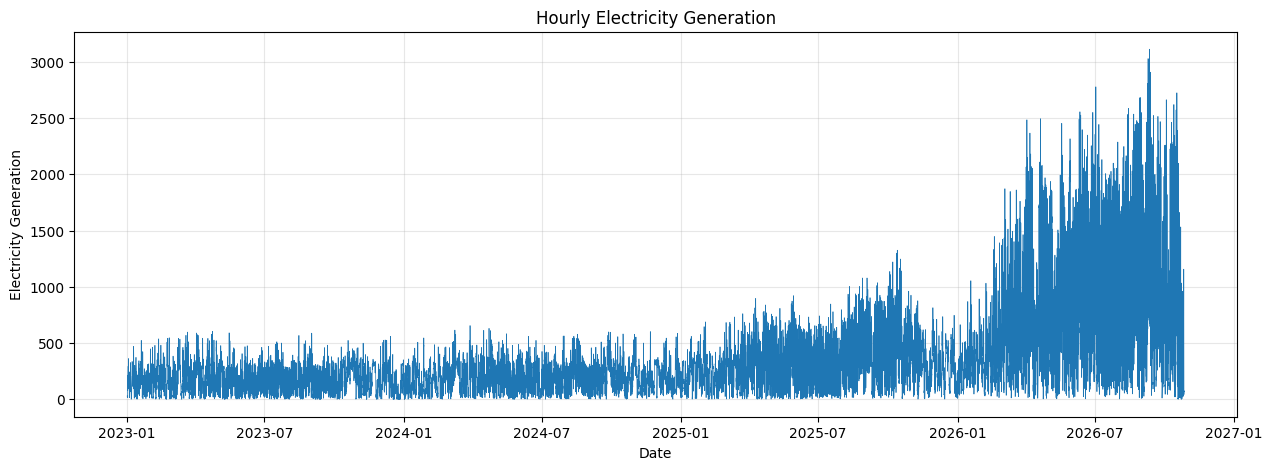

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(data["ds"], data["y"], linewidth=0.5)

plt.title("Hourly Electricity Generation")
plt.xlabel("Date")
plt.ylabel("Electricity Generation")
plt.grid(alpha=0.3)

plt.show()

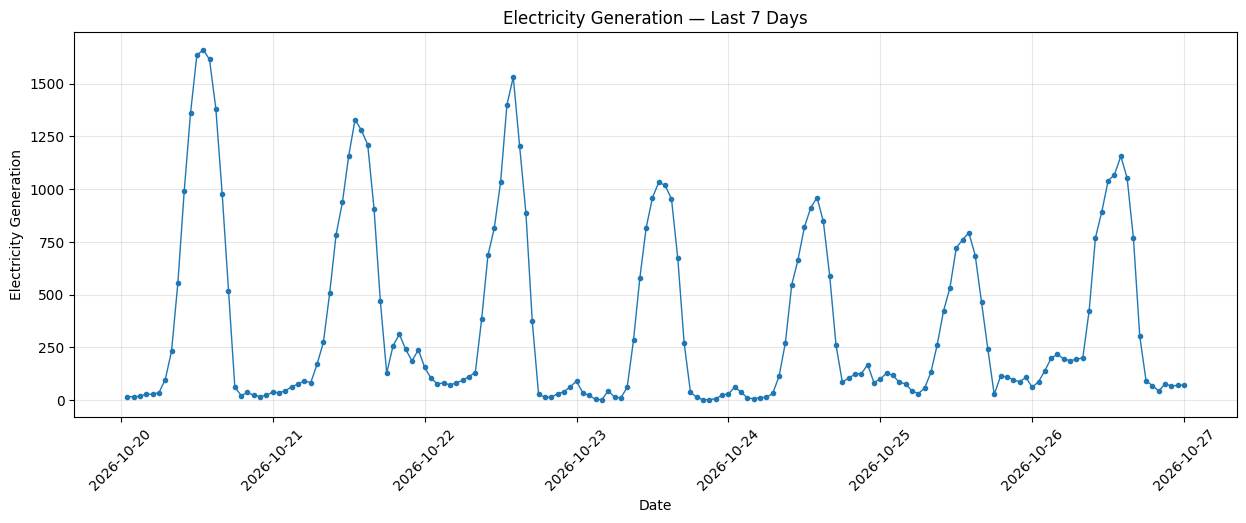

In [6]:
last_week = data.tail(24 * 7)

plt.figure(figsize=(15, 5))

plt.plot(
    last_week["ds"],
    last_week["y"],
    marker=".",
    linewidth=1
)

plt.title("Electricity Generation — Last 7 Days")
plt.xlabel("Date")
plt.ylabel("Electricity Generation")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

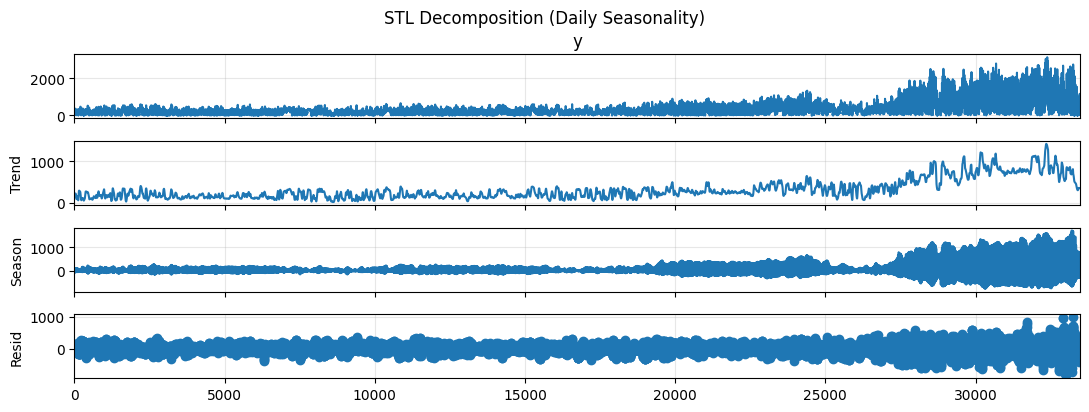

In [7]:
from statsmodels.tsa.seasonal import STL

y = data["y"].astype(float)

stl = STL(y, period=24, robust=True)
result = stl.fit()

result.plot()

plt.suptitle("STL Decomposition (Daily Seasonality)", y=1.02)
plt.show()

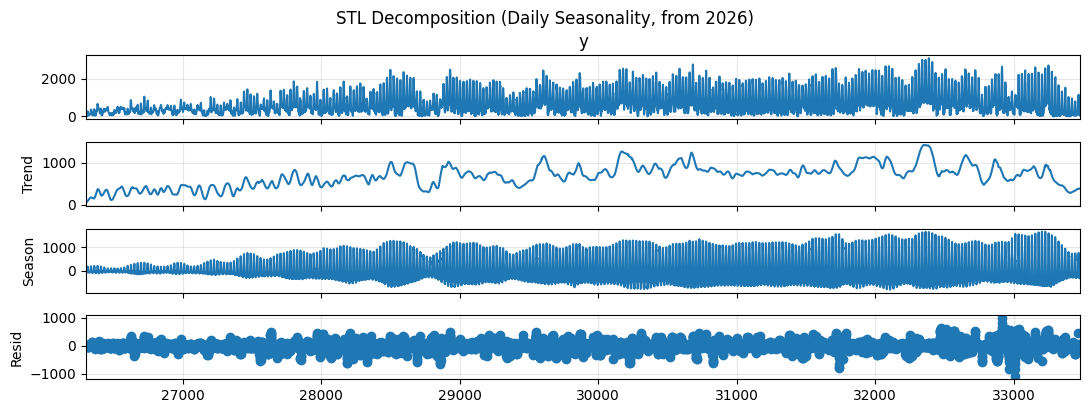

In [8]:

data_2026 = data[data["ds"] >= "2026-01-01"].copy()

y_2026 = data_2026["y"].astype(float)

stl = STL(
    y_2026,
    period=24,
    robust=True
)

result = stl.fit()
result.plot()

plt.suptitle(
    "STL Decomposition (Daily Seasonality, from 2026)",y=1.02)

plt.show()


##1. What is in the series?

**plot 1** - The time plot shows an increasing trend in electricity generation, especially from 2025. The series has strong daily seasonality, with high values during the day and low values at night. The fluctuations become larger over time, especially in 2026.

**plot 2, Last 7 days** - The plot shows a clear daily pattern. Electricity generation increases during the day and drops at night. The pattern repeats every day, but the peak values are different. This shows that daily seasonality is important for forecasting.

**plot 3, Full STL** - The STL decomposition shows the trend, seasonal component, and residuals.

The trend shows an increase in electricity generation, especially from 2025. The seasonal component shows a strong daily pattern with larger fluctuations over time. The residuals contain irregular changes that are not explained by the trend and seasonality. Their variability also increases towards the end of the series.

**plot 4, STL from 2026**
I focus on 2026 because the changes in generation are more visible during this period. This helps us better understand the recent patterns in the series. The increasing fluctuations suggest that a variance-stabilizing transformation may be useful.

The trend shows an overall increase in electricity generation, especially in 2026. The seasonal component shows a strong daily pattern, with high values during the day and low values at night. The seasonal fluctuations and residuals become larger over time.

# 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

## HistGradientBoostingRegressor

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error

# 1. PREPARE DATA

H = 48
LOOKBACK = 168

# Historical data
df = data.copy().reset_index(drop=True)

# Future weather forecast
future = pd.read_csv("weather_forecast.csv")

# Convert dates
df["ds"] = pd.to_datetime(df["ds"])
future["ds"] = pd.to_datetime(future["ds"])

# Sort by date
df = df.sort_values("ds").reset_index(drop=True)
future = future.sort_values("ds").reset_index(drop=True)

# Weather variables
weather_cols = [
    "cloud_cover",
    "temperature",
    "wind_speed",
    "pressure",
    "humidity",
    "daylight",
    "air_density"
]

# Check data
assert len(future) == H, f"Expected 48 future rows, got {len(future)}"

assert df["ds"].is_monotonic_increasing
assert future["ds"].is_monotonic_increasing

assert df["ds"].is_unique
assert future["ds"].is_unique

assert not df[["ds", "y"] + weather_cols].isna().any().any()
assert not future[["ds"] + weather_cols].isna().any().any()

# Ensure future starts exactly one hour after historical data
assert future["ds"].iloc[0] == df["ds"].iloc[-1] + pd.Timedelta(hours=1)

assert (
    future["ds"].diff().dropna() == pd.Timedelta(hours=1)
).all()

# Target
y = df["y"].to_numpy(dtype=float)

print("Historical observations:", len(df))
print("Future observations:", len(future))
print("Last historical hour:", df["ds"].iloc[-1])
print("Forecast starts:", future["ds"].iloc[0])
print("Forecast ends:", future["ds"].iloc[-1])


Historical observations: 33480
Future observations: 48
Last historical hour: 2026-10-27 00:00:00
Forecast starts: 2026-10-27 01:00:00
Forecast ends: 2026-10-29 00:00:00


In [10]:
# 2. CREATE FEATURES

def make_features(row, history):

    X = row[weather_cols].copy()

    # Daily seasonality
    hour = row["ds"].dt.hour

    X["hour_sin"] = np.sin(  2 * np.pi * hour / 24)

    X["hour_cos"] = np.cos(   2 * np.pi * hour / 24 )

    # Annual seasonality
    day = row["ds"].dt.dayofyear

    X["day_sin"] = np.sin(2 * np.pi * day / 365.25)

    X["day_cos"] = np.cos(  2 * np.pi * day / 365.25)

    # Historical generation
    history = np.asarray(history, dtype=float)

    X["lag24"] = history[-24]
    X["lag48"] = history[-48]
    X["lag168"] = history[-168]

    return X

In [11]:
# 3. METRICS

def calculate_metrics(actual, forecast, lower, upper):

    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)

    lower = np.asarray(lower, dtype=float)
    upper = np.asarray(upper, dtype=float)

    # RMSE
    rmse = np.sqrt(mean_squared_error(actual, forecast))

    nonzero = actual != 0

    if nonzero.any():
        mape = 100 * np.mean( np.abs((actual[nonzero] - forecast[nonzero]) / actual[nonzero]))
    else:
        mape = np.nan

    # 95% interval coverage
    coverage = np.mean( (actual >= lower) & (actual <= upper))
    # Winkler score
    alpha = 0.05
    winkler = (   (upper - lower)+ (2 / alpha) * np.maximum(lower - actual, 0)    + (2 / alpha) * np.maximum(actual - upper, 0))
    winkler = np.mean(winkler)
    return {
        "RMSE": rmse,
        "MAPE": mape,
        "Winkler": winkler,
        "Coverage": coverage
    }

In [12]:
# 4. VALIDATION SPLIT

# Last 48 historical hours are held out
train_end = len(df) - H

train_df = df.iloc[:train_end].copy()

valid_df = df.iloc[train_end:].copy()

y_train_full = y[:train_end]

y_valid = y[train_end:]

print("\nValidation period:")
print(valid_df["ds"].iloc[0], "to", valid_df["ds"].iloc[-1])

# 5. CREATE VALIDATION TRAINING DATA

X_train_list = []
y_train_list = []

for i in range(LOOKBACK, train_end):

    row = df.iloc[[i]]
    history = y[:i]
    features = make_features(  row,  history)
    X_train_list.append( features.iloc[0].to_numpy(dtype=float))
    y_train_list.append( y[i])

X_train = np.array(X_train_list)

y_train = np.array(y_train_list)

print("\nValidation training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

# 6. TRAIN VALIDATION MODEL

model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

model.fit(X_train,y_train)



Validation period:
2026-10-25 01:00:00 to 2026-10-27 00:00:00

Validation training data:
X_train: (33264, 14)
y_train: (33264,)


HistGradientBoostingRegressor(l2_regularization=1.0, learning_rate=0.08,
                              max_iter=200, max_leaf_nodes=15, random_state=42)

In [13]:
# 7. VALIDATION FORECAST

history_val = list(y_train_full)
forecast_val = []
for i in range(H):

    row = valid_df.iloc[[i]]

    features = make_features(
        row,
        history_val
    )

    pred = model.predict(features)[0]

    pred = max(0, pred)

    forecast_val.append(pred)

    # Recursive forecast
    history_val.append(pred)

forecast_val = np.array(forecast_val)


In [14]:
# 8. SEASONAL NAIVE BENCHMARK

# Repeat the last 24 observed hours twice
baseline_val = np.tile(y_train_full[-24:],2)

# Compare forecasts
rmse_model = np.sqrt( mean_squared_error( y_valid, forecast_val))

rmse_baseline = np.sqrt( mean_squared_error( y_valid,baseline_val))

skill = rmse_model / rmse_baseline

print("\n================ VALIDATION RESULTS ================")
print("HistGradientBoosting RMSE:", round(rmse_model, 3))
print("Seasonal Naive RMSE:", round(rmse_baseline, 3))
print("Skill:", round(skill, 4))
print("Beats benchmark:", skill < 1)


================ VALIDATION RESULTS ================
HistGradientBoosting RMSE: 110.353
Seasonal Naive RMSE: 120.404
Skill: 0.9165
Beats benchmark: True


In [15]:
# 9. VALIDATION PREDICTION INTERVAL
# Validation residuals
residuals = y_valid - forecast_val

# Empirical residual quantiles
q_lower = np.quantile(residuals,0.025)

q_upper = np.quantile(residuals,0.975)

lower_val = np.maximum(forecast_val + q_lower,0)

upper_val = np.maximum(forecast_val + q_upper,forecast_val)

# Calculate all metrics
validation_scores = calculate_metrics(
    y_valid,
    forecast_val,
    lower_val,
    upper_val
)

print("\nValidation metrics:")
print( pd.Series(validation_scores).round(3))
print("\n95% interval coverage:")
print(round(validation_scores["Coverage"], 3))


Validation metrics:
RMSE        110.353
MAPE         39.676
Winkler     454.373
Coverage      0.917
dtype: float64

95% interval coverage:
0.917


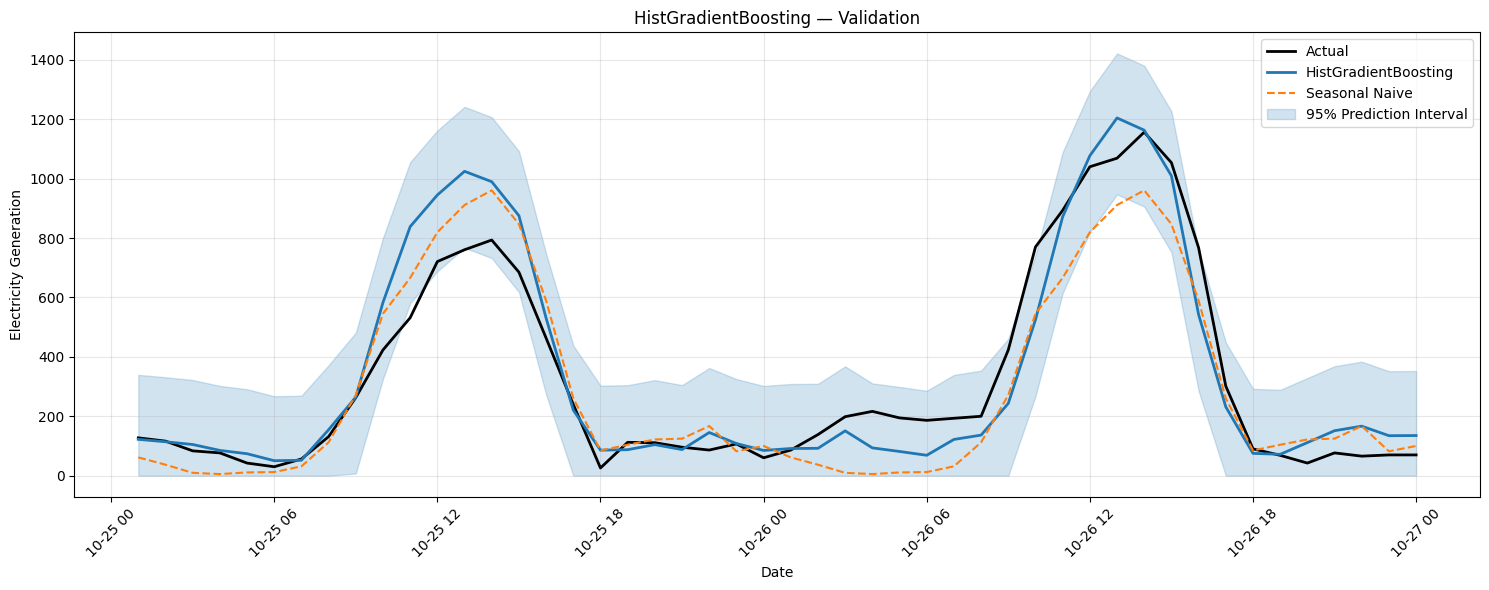

In [16]:
# 10. VALIDATION PLOT

plt.figure(figsize=(15, 6))

plt.plot(
    valid_df["ds"],
    y_valid,
    color="black",
    linewidth=2,
    label="Actual"
)

plt.plot(
    valid_df["ds"],
    forecast_val,
    color="tab:blue",
    linewidth=2,
    label="HistGradientBoosting"
)

plt.plot(
    valid_df["ds"],
    baseline_val,
    color="tab:orange",
    linestyle="--",
    label="Seasonal Naive"
)

plt.fill_between(
    valid_df["ds"],
    lower_val,
    upper_val,
    color="tab:blue",
    alpha=0.2,
    label="95% Prediction Interval"
)

plt.title("HistGradientBoosting — Validation")
plt.xlabel("Date")
plt.ylabel("Electricity Generation")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Final training data:
X_final: (33312, 14)
y_final: (33312,)


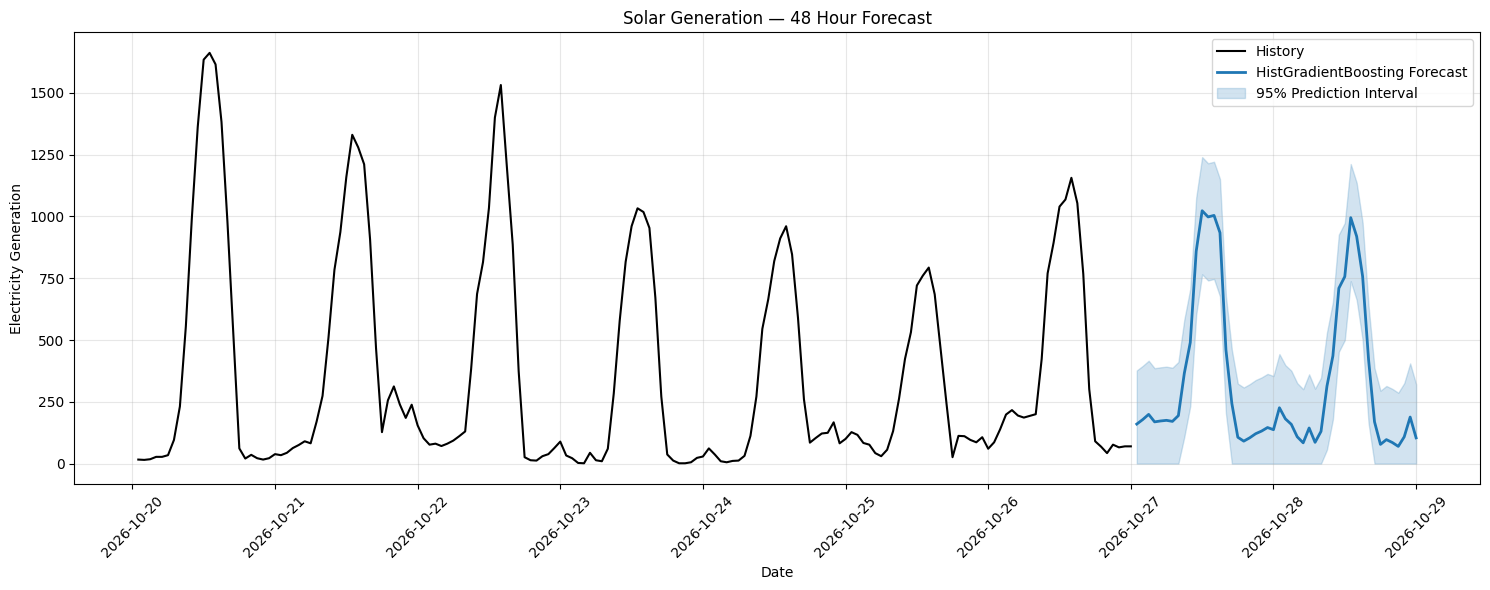


All final forecast checks passed!

Forecast shape: (48,)
Lower interval shape: (48,)
Upper interval shape: (48,)

Forecast:
[ 160.04484377  178.23425966  199.27990296  168.96308355  172.59830779
  175.14632035  170.91779779  194.23525949  365.61603096  489.71522976
  859.38172091 1023.07631447  998.06374876 1004.20968566  934.1390857
  460.60229825  242.96933553  106.74361087   90.97396879  104.37767061
  120.99662284  131.70983648  146.02526813  137.35934941  226.10366254
  181.24256953  159.09418812  108.49847672   84.16339905  144.1903766
   86.15028193  130.46315099  313.48746198  436.08631504  709.58597038
  756.69309113  995.09341534  919.18409984  757.64879964  420.93184249
  169.3427741    77.79892763   97.08121572   85.40514105   69.73339714
  108.35917653  188.38152197  104.24360866]

Lower 95%:
[  0.           0.           0.           0.           0.
   0.           0.           0.         108.53822418 232.63742299
 602.30391414 765.99850769 740.98594198 747.13187889 677.0

In [17]:

# 11. TRAIN FINAL MODEL ON ALL HISTORICAL DATA

X_final_list = []
y_final_list = []

for i in range(LOOKBACK, len(df)):
    row = df.iloc[[i]]
    history = y[:i]
    features = make_features( row,history)
    X_final_list.append( features.iloc[0].to_numpy(dtype=float))
    y_final_list.append(y[i])

X_final = np.array(X_final_list)
y_final = np.array(y_final_list)

print("\nFinal training data:")
print("X_final:", X_final.shape)
print("y_final:", y_final.shape)

# Train on all available history
final_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

final_model.fit( X_final,y_final)

# 12. FORECAST NEXT 48 HOURS

history = list(y)

forecast = []

for i in range(H):
    row = future.iloc[[i]]
    features = make_features( row, history)
    pred = final_model.predict(features)[0]
    pred = max(0, pred)
    forecast.append(pred)
    history.append(pred)

forecast = np.array(forecast)

# 13. FINAL 95% PREDICTION INTERVAL

lower_95 = np.maximum( forecast + q_lower, 0)
upper_95 = np.maximum(forecast + q_upper,forecast)
lower_95 = np.minimum( lower_95,forecast)
upper_95 = np.maximum(upper_95,forecast)

# 14. FINAL FORECAST PLOT

FUTURE = future["ds"]

plt.figure(figsize=(15, 6))

plt.plot(
    df["ds"].iloc[-7 * 24:],
    y[-7 * 24:],
    color="black",
    linewidth=1.5,
    label="History"
)

plt.plot(
    FUTURE,
    forecast,
    color="tab:blue",
    linewidth=2,
    label="HistGradientBoosting Forecast"
)

plt.fill_between(
    FUTURE,
    lower_95,
    upper_95,
    color="tab:blue",
    alpha=0.2,
    label="95% Prediction Interval"
)

plt.title("Solar Generation — 48 Hour Forecast")
plt.xlabel("Date")
plt.ylabel("Electricity Generation")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 15. CHECK FINAL FORECAST

assert len(forecast) == H
assert len(lower_95) == H
assert len(upper_95) == H

assert np.isfinite(forecast).all()
assert np.isfinite(lower_95).all()
assert np.isfinite(upper_95).all()

assert (forecast >= 0).all()
assert (lower_95 >= 0).all()

assert (lower_95 <= forecast).all()
assert (forecast <= upper_95).all()

assert np.array_equal(
    pd.to_datetime(FUTURE).to_numpy(),
    pd.to_datetime(future["ds"]).to_numpy()
)

print("\nAll final forecast checks passed!")


# ============================================================
# 16. OUTPUT ARRAYS
print("\nForecast shape:", forecast.shape)
print("Lower interval shape:", lower_95.shape)
print("Upper interval shape:", upper_95.shape)
print("\nForecast:")
print(forecast)
print("\nLower 95%:")
print(lower_95)
print("\nUpper 95%:")
print(upper_95)


# SEASONAL REGRESSION + XGBOOST RESIDUAL


In [18]:

!pip -q install xgboost


In [19]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

# 1. Prepare data

df = data.copy()
df["ds"] = pd.to_datetime(df["ds"])
df = df.sort_values("ds").reset_index(drop=True)
df["y"] = df["y"].astype(float)
H = 48
# Same validation window as the benchmark
train_val = df.iloc[:-H].copy()
valid = df.iloc[-H:].copy()

# 2. Feature engineering

weather_cols = [
    "cloud_cover",
    "temperature",
    "wind_speed",
    "pressure",
    "humidity",
    "daylight",
    "air_density"
]

feature_cols = [
    "trend",
    "hour_sin", "hour_cos",
    "week_sin", "week_cos",
    "year_sin", "year_cos",
    "month",
    "cloud_cover",
    "temperature",
    "wind_speed",
    "pressure",
    "humidity",
    "daylight",
    "air_density",
    "lag_24",
    "lag_48",
    "lag_168"
]

def make_features(frame):

    frame = frame.copy()

    ds = pd.to_datetime(frame["ds"])

    # Trend
    frame["trend"] = ((ds - pd.Timestamp("2023-01-01"))/ pd.Timedelta(hours=1)).astype(float)
    # Daily seasonality
    hour = ds.dt.hour
    frame["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    frame["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    # Weekly seasonality
    dow = ds.dt.dayofweek
    frame["week_sin"] = np.sin(2 * np.pi * dow / 7)
    frame["week_cos"] = np.cos(2 * np.pi * dow / 7)
    # Annual seasonality
    doy = ds.dt.dayofyear
    frame["year_sin"] = np.sin(2 * np.pi * doy / 365.25)
    frame["year_cos"] = np.cos(2 * np.pi * doy / 365.25)
    frame["month"] = ds.dt.month
    # Ensure weather columns exist
    for col in weather_cols:
        if col not in frame.columns:
            frame[col] = np.nan
        frame[col] = pd.to_numeric(
            frame[col],
            errors="coerce"
        )
    return frame

# 3. Create historical features

X_all = make_features(df)

# Lagged electricity generation
X_all["lag_24"] = df["y"].shift(24)
X_all["lag_48"] = df["y"].shift(48)
X_all["lag_168"] = df["y"].shift(168)

X_all = X_all[feature_cols]

valid_idx = X_all.dropna().index
X_all = X_all.loc[valid_idx].reset_index(drop=True)
y_all = df.loc[valid_idx, "y"].reset_index(drop=True)


Fold 1: train=19958, valid=2661
Fold 2: train=22619, valid=2661
Fold 3: train=25280, valid=2661
Fold 4: train=27941, valid=2661
Fold 5: train=30602, valid=2662

VALIDATION RESULTS


,Model,RMSE
0,Seasonal Regression + XGBoost,93.995
1,Seasonal Naive,120.404
2,Seasonal Regression,141.924


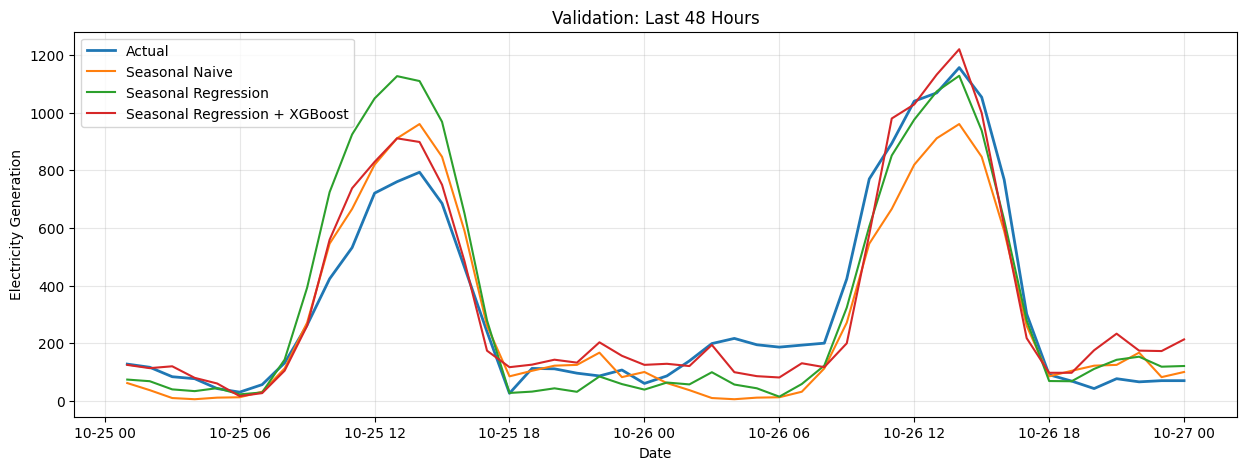

Fold 1: train=19987, valid=2665
Fold 2: train=22652, valid=2665
Fold 3: train=25317, valid=2665
Fold 4: train=27982, valid=2665
Fold 5: train=30647, valid=2665

FINAL FORECAST
[ 206.08346457  217.10662296  244.69998815  243.72636577  233.86680777
  224.57449956  202.5433735   276.00471083  501.05981589  689.89331316
  963.50992214 1203.94037384 1164.20363623 1118.34388725  982.2462426
  490.94480131  247.87894191  117.13853178  117.62608208   89.21380185
  156.09744587  125.43759319  211.72310054  142.10429703  302.11264008
  226.15995867  204.47088937  126.88958013   66.75619241  159.27538753
   21.05972894  101.32269189  364.28738388  483.97495881  761.30109018
  989.18637655 1134.64942737 1113.84009336  893.55777167  463.94049664
   97.10606248   46.63434668  128.13005423   85.92110509   31.16639753
   89.65765503  241.46449668  124.23282206]

Submission created:


,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,206.083,50.840,393.247
1,2026-10-27 02:00:00,217.107,61.864,404.270
2,2026-10-27 03:00:00,244.700,89.457,431.863
3,2026-10-27 04:00:00,243.726,88.483,430.890
4,2026-10-27 05:00:00,233.867,78.624,421.030



Saved as Lanina_project.csv


In [20]:
# 4. Seasonal Regression

def create_sr():
    return make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0))

# 5. XGBoost Residual
def create_xgb():

    return XGBRegressor(
        n_estimators=700,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

# 6. Generate out-of-fold residuals

# We do not train XGBoost on in-sample residuals.
# Instead, we generate residuals from chronological folds.

def get_oof_residuals(X, y):
    n = len(X)
    initial_size = int(n * 0.60)
    remaining = n - initial_size
    n_folds = 5
    fold_size = remaining // n_folds
    oof_residuals = []
    oof_features = []
    for fold in range(n_folds):
        start = initial_size + fold * fold_size
        if fold == n_folds - 1:
            end = n
        else:
            end = start + fold_size
        if start == 0 or end <= start:
            continue
        X_fold_train = X.iloc[:start]
        y_fold_train = y.iloc[:start]
        X_fold_valid = X.iloc[start:end]
        y_fold_valid = y.iloc[start:end]
        sr = create_sr()
        sr.fit(X_fold_train,y_fold_train)
        pred = sr.predict(X_fold_valid)
        residual = (y_fold_valid.to_numpy() - pred)
        oof_residuals.extend(residual)
        oof_features.append(X_fold_valid.copy())
        print(
            f"Fold {fold + 1}: "
            f"train={len(X_fold_train)}, "
            f"valid={len(X_fold_valid)}"
        )
    X_oof = pd.concat(oof_features,ignore_index=True)
    y_oof = np.asarray(oof_residuals)
    return X_oof, y_oof

# 7. Forecast function

def forecast_model(history, future_weather):

    history = history.copy()
    history["ds"] = pd.to_datetime(
        history["ds"]
    )
    history = history.sort_values(
        "ds"
    ).reset_index(drop=True)
    future_weather = future_weather.copy()
    future_weather["ds"] = pd.to_datetime(
        future_weather["ds"]
    )
    future_weather = future_weather.sort_values(
        "ds"
    ).reset_index(drop=True)
    # Create historical features
    X_hist = make_features(history)
    X_hist["lag_24"] = history["y"].shift(24)
    X_hist["lag_48"] = history["y"].shift(48)
    X_hist["lag_168"] = history["y"].shift(168)
    X_hist = X_hist[feature_cols]
    idx = X_hist.dropna().index
    X_hist = X_hist.loc[idx].reset_index(drop=True)
    y_hist = history.loc[
        idx, "y"
    ].reset_index(drop=True)
    # Generate chronological OOF residuals
    X_oof, residual_oof = get_oof_residuals(
        X_hist,
        y_hist
    )
    # Fit final Seasonal Regression
    sr = create_sr()
    sr.fit(X_hist,y_hist)
    # Fit XGBoost on out-of-fold residuals
    xgb = create_xgb()
    xgb.fit(X_oof,residual_oof)
    # Recursive forecasting
    history_y = history["y"].astype(float).tolist()
    predictions_sr = []
    predictions_residual = []
    predictions_final = []
    for i in range(len(future_weather)):
        row = future_weather.iloc[[i]].copy()
        row = make_features(row)
        row["lag_24"] = history_y[-24]
        row["lag_48"] = history_y[-48]
        row["lag_168"] = history_y[-168]
        X_future = row[feature_cols]
        # Seasonal Regression
        sr_pred = sr.predict(
            X_future
        )[0]
        # XGBoost residual
        residual_pred = xgb.predict(
            X_future
        )[0]
        # Combined forecast
        final_pred = max(
            0,
            sr_pred + residual_pred
        )
        predictions_sr.append(sr_pred)
        predictions_residual.append(
            residual_pred
        )
        predictions_final.append(
            final_pred
        )
        # Update history recursively
        history_y.append(final_pred)

    return (
        np.array(predictions_sr),
        np.array(predictions_residual),
        np.array(predictions_final)
    )

# 8. Validation: last 48 historical hours

weather_validation = valid[
    ["ds"] + weather_cols
].copy()

sr_valid, residual_valid, combined_valid = (
    forecast_model(
        train_val,
        weather_validation
    )
)

actual_valid = valid["y"].to_numpy()

# 9. Compare RMSE

def rmse(actual, predicted):
    return np.sqrt(
        np.mean(
            (np.asarray(actual) -
             np.asarray(predicted)) ** 2
        )
    )

history = train_val["y"].to_numpy()

benchmark = np.array([
    history[-24 + (i % 24)]
    for i in range(H)
])

# Calculate RMSE
results = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "Seasonal Regression",
        "Seasonal Regression + XGBoost"
    ],

    "RMSE": [
        rmse(actual_valid, benchmark),
        rmse(actual_valid, sr_valid),
        rmse(actual_valid, combined_valid)
    ]
})

results = results.sort_values(
    "RMSE"
).reset_index(drop=True)

print("\nVALIDATION RESULTS")
display(results)

# 10. Plot validation forecasts

plt.figure(figsize=(15, 5))

plt.plot(
    valid["ds"],
    actual_valid,
    label="Actual",
    linewidth=2
)

plt.plot(
    valid["ds"],
    benchmark,
    label="Seasonal Naive"
)

plt.plot(
    valid["ds"],
    sr_valid,
    label="Seasonal Regression"
)

plt.plot(
    valid["ds"],
    combined_valid,
    label="Seasonal Regression + XGBoost"
)

plt.title("Validation: Last 48 Hours")

plt.xlabel("Date")
plt.ylabel("Electricity Generation")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

# 11. Final forecast: hidden 48 hours

# Now we use the complete history
# and the provided weather forecast.

final_sr, final_residual, final_forecast = ( forecast_model(data,weather_fc))
print("\nFINAL FORECAST")
print(final_forecast)

# 12. Prediction intervals
validation_errors = (actual_valid - combined_valid)
q_lower = np.quantile(validation_errors,0.025)
q_upper = np.quantile(validation_errors,0.975)
lower_95 = np.maximum(0,final_forecast + q_lower)
upper_95 = np.maximum( lower_95,final_forecast + q_upper)

# 13. Submission file

SURNAME = "Lanina"

submission = pd.DataFrame({
    "ds": pd.to_datetime(
        weather_fc["ds"]
    ),
    "forecast": final_forecast,
    "lower_95": lower_95,
    "upper_95": upper_95})

submission.to_csv(
    f"{SURNAME}_project.csv",
    index=False
)

print("\nSubmission created:")
display(submission.head())

print(
    f"\nSaved as {SURNAME}_project.csv"
)


In [21]:
# FINAL MODEL + HIDDEN HORIZON + SUBMISSION

# 1. Prepare future timestamps
FUTURE = pd.to_datetime(weather_fc["ds"]).reset_index(drop=True)

H = 48
SURNAME = "Lanina"

# 2. Train final model on FULL history
final_sr, final_residual, final_forecast = forecast_model(
    history=data,
    future_weather=weather_fc)
forecast = np.maximum(0,final_forecast)

# 3. Calculate 95% prediction intervals

validation_errors = (np.asarray(actual_valid)- np.asarray(combined_valid))
q_lower = np.quantile(validation_errors,0.025)
q_upper = np.quantile(validation_errors,0.975)
lower_95 = np.maximum(0,forecast + q_lower)
upper_95 = np.maximum(lower_95,forecast + q_upper)
# 4. Create submission checker

def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds","forecast", "lower_95","upper_95"], "wrong columns"
    assert len(sub) == H, (f"need {H} rows, got {len(sub)}")
    assert (pd.to_datetime(sub["ds"]).to_numpy()== FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert ((sub["lower_95"] <= sub["forecast"]).all()and(sub["forecast"] <= sub["upper_95"]).all()), "the forecast must lie inside its interval"
    print("format OK")

# 5. Create submission
submission = pd.DataFrame({
    "ds": FUTURE.dt.strftime(
        "%Y-%m-%d %H:%M:%S"),
    "forecast": forecast,
    "lower_95": lower_95,
    "upper_95": upper_95
})

check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"

submission.to_csv(FILE,index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass
display(submission)

Fold 1: train=19987, valid=2665
Fold 2: train=22652, valid=2665
Fold 3: train=25317, valid=2665
Fold 4: train=27982, valid=2665
Fold 5: train=30647, valid=2665
format OK
saved LANINA_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,206.083,50.840,393.247
1,2026-10-27 02:00:00,217.107,61.864,404.270
2,2026-10-27 03:00:00,244.700,89.457,431.863
3,2026-10-27 04:00:00,243.726,88.483,430.890
4,2026-10-27 05:00:00,233.867,78.624,421.030
5,2026-10-27 06:00:00,224.574,69.331,411.738
6,2026-10-27 07:00:00,202.543,47.300,389.707
7,2026-10-27 08:00:00,276.005,120.762,463.168
8,2026-10-27 09:00:00,501.060,345.817,688.223
9,2026-10-27 10:00:00,689.893,534.650,877.057


## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

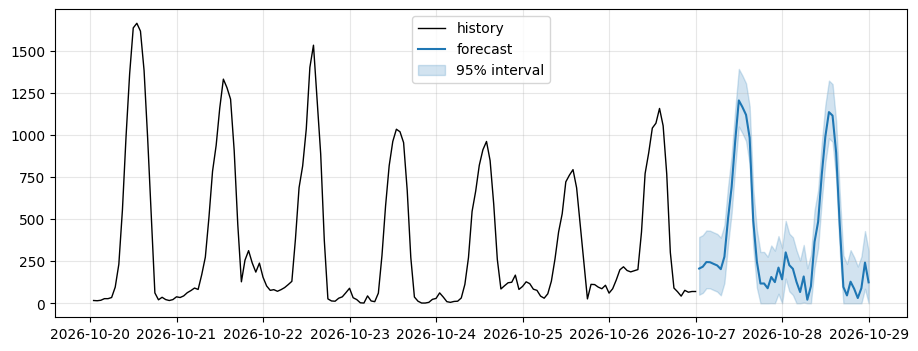

In [22]:

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

# Lightgbm

Validation RMSE
LightGBM: 90.878
Seasonal Naive: 120.404


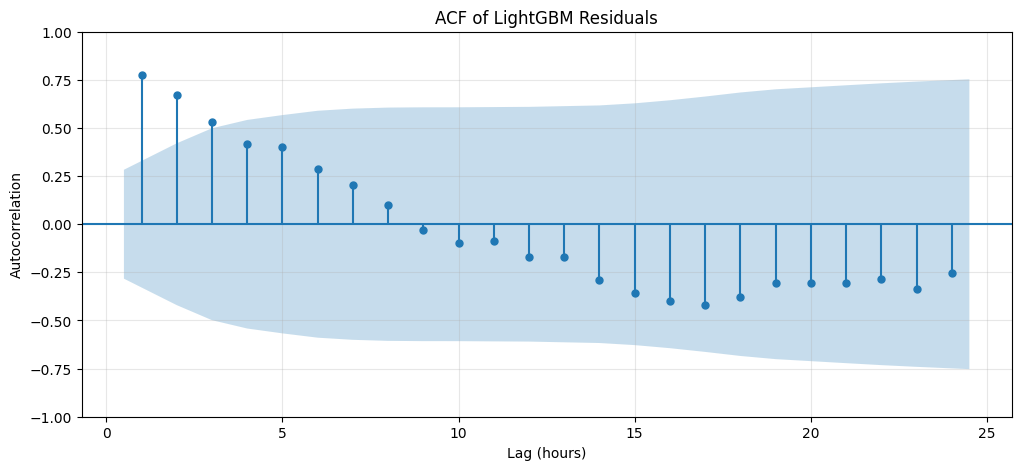

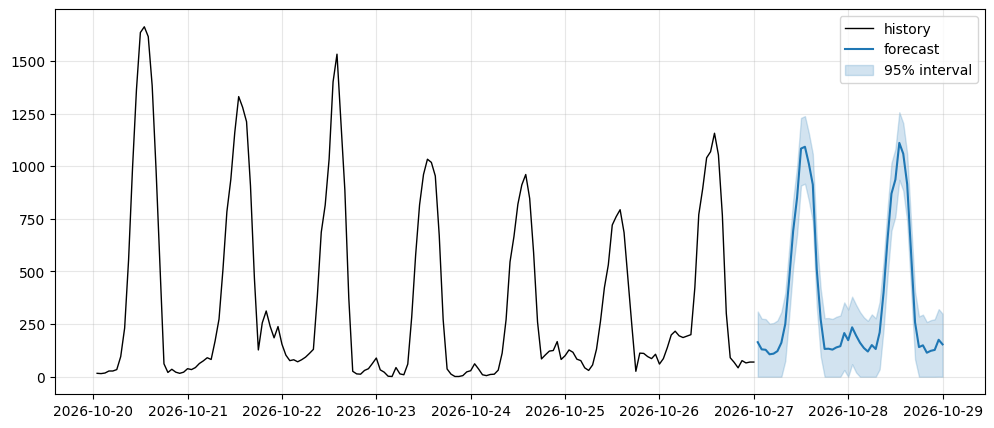

format OK
Saved: LANINA_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:

from lightgbm import LGBMRegressor

# ============================================================
# 1. FEATURES

WEATHER = [
    "cloud_cover", "temperature", "wind_speed",
    "pressure", "humidity", "daylight", "air_density"
]

LAGS = [24, 48, 72, 168, 336]
ROLLS = [24, 48, 168, 336]

FEATURES = WEATHER + [
    "hour_sin", "hour_cos",
    "dow_sin", "dow_cos",
    "year_sin", "year_cos",
    "lag24", "lag48", "lag72", "lag168", "lag336",
    "mean24", "mean48", "mean168", "mean336",
    "std24", "std168",
    "diff24", "diff168"
]


def time_features(df):
    df = df.copy()

    hour = df["ds"].dt.hour
    dow = df["ds"].dt.dayofweek
    year = df["ds"].dt.dayofyear
    df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    df["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    df["dow_sin"] = np.sin(2 * np.pi * dow / 7)
    df["dow_cos"] = np.cos(2 * np.pi * dow / 7)
    df["year_sin"] = np.sin(2 * np.pi * year / 365.25)
    df["year_cos"] = np.cos(2 * np.pi * year / 365.25)
    return df


def make_features(df):
    df = time_features(df)
    y = df["y"].astype(float)
    for lag in LAGS:
        df[f"lag{lag}"] = y.shift(lag)
    for window in ROLLS:
        shifted = y.shift(1)
        df[f"mean{window}"] = shifted.rolling(window).mean()
        if window in [24, 168]:
            df[f"std{window}"] = shifted.rolling(window).std()
    df["diff24"] = df["lag24"] - df["lag48"]
    df["diff168"] = df["lag168"] - df["lag336"]
    return df.dropna()

# 2. MODEL

def build_model(seed):

    return LGBMRegressor(
        objective="regression",
        n_estimators=1000,
        learning_rate=0.025,
        num_leaves=63,
        max_depth=-1,
        min_child_samples=30,
        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=2,
        random_state=seed,
        n_jobs=-1,
        verbosity=-1
    )

# 3. RECURSIVE FORECAST

def predict(history, future_weather, models):

    values = history["y"].astype(float).tolist()
    predictions = []
    for _, row in future_weather.iterrows():
        x = time_features(pd.DataFrame([row]))
        for lag in LAGS:
            x[f"lag{lag}"] = values[-lag]
        for window in ROLLS:
            recent = np.array(values[-window:])
            x[f"mean{window}"] = recent.mean()
            if window in [24, 168]:
                x[f"std{window}"] = recent.std(ddof=1)
        x["diff24"] = x["lag24"] - x["lag48"]
        x["diff168"] = x["lag168"] - x["lag336"]
        pred = np.mean([
            model.predict(x[FEATURES])[0]
            for model in models
        ])
        pred = max(0, pred)
        predictions.append(pred)
        values.append(pred)
    return np.array(predictions)
# 4. VALIDATION

train = data.iloc[:-H].copy()
valid = data.iloc[-H:].copy()
train_features = make_features(train)
# Give more importance to recent observations
age = np.arange(len(train_features))[::-1]
weights = np.exp(-np.log(2) * age / (24 * 180))

models = []

for seed in [42, 123, 2026]:
    model = build_model(seed)
    model.fit(
        train_features[FEATURES],
        train_features["y"],
        sample_weight=weights
    )
    models.append(model)
val_forecast = predict(
    train,
    valid[["ds"] + WEATHER],
    models
)
bench_forecast, _, _ = snaive(train["y"].to_numpy())
print("Validation RMSE")
print("LightGBM:", round(rmse(valid["y"], val_forecast), 3))
print("Seasonal Naive:", round(rmse(valid["y"], bench_forecast), 3))

# 5. FINAL MODEL ON ALL HISTORY

final_features = make_features(data)
age = np.arange(len(final_features))[::-1]
weights = np.exp(-np.log(2) * age / (24 * 180))
final_models = []

for seed in [42, 123, 2026]:
    model = build_model(seed)
    model.fit(
        final_features[FEATURES],
        final_features["y"],
        sample_weight=weights
    )
    final_models.append(model)
forecast = predict(
    data,
    weather_fc[["ds"] + WEATHER],
    final_models
)
# ============================================================
# RESIDUALS ACF

from statsmodels.graphics.tsaplots import plot_acf

residuals = valid["y"].to_numpy() - val_forecast

fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    residuals,
    lags=24,
    alpha=0.05,
    zero=False,
    ax=ax
)

ax.set_title("ACF of LightGBM Residuals")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")

plt.show()

# 6. 95% PREDICTION INTERVAL

errors = valid["y"].to_numpy() - val_forecast
q_lower, q_upper = np.quantile(errors, [0.025, 0.975])
q_lower = min(q_lower, 0)
q_upper = max(q_upper, 0)
lower_95 = np.maximum(forecast + q_lower, 0)
upper_95 = np.maximum(forecast + q_upper, forecast)


# 7. PLOT

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    data["ds"].iloc[-7 * M:],
    data["y"].iloc[-7 * M:],
    color="black",
    lw=1,
    label="history"
)

ax.plot(
    FUTURE,
    forecast,
    color="tab:blue",
    label="forecast"
)

ax.fill_between(
    FUTURE,
    lower_95,
    upper_95,
    color="tab:blue",
    alpha=0.2,
    label="95% interval"
)

ax.legend()
plt.show()

# 8. SUBMISSION

submission = pd.DataFrame({
    "ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"),
    "forecast": forecast,
    "lower_95": lower_95,
    "upper_95": upper_95
})
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"

submission.to_csv(FILE, index=False)

print("Saved:", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass


#Methodology and diagnostics(all in one)
## 1. What is in the series?

**plot 1** - The time plot shows an increasing trend in electricity generation, especially from 2025. The series has strong daily seasonality, with high values during the day and low values at night. The fluctuations become larger over time, especially in 2026.

**plot 2, Last 7 days** - The plot shows a clear daily pattern. Electricity generation increases during the day and drops at night. The pattern repeats every day, but the peak values are different. This shows that daily seasonality is important for forecasting.

**plot 3, Full STL** - The STL decomposition shows the trend, seasonal component, and residuals.

The trend shows an increase in electricity generation, especially from 2025. The seasonal component shows a strong daily pattern with larger fluctuations over time. The residuals contain irregular changes that are not explained by the trend and seasonality. Their variability also increases towards the end of the series.

**plot 4, STL from 2026**
I focus on 2026 because the changes in generation are more visible during this period. This helps us better understand the recent patterns in the series. The increasing fluctuations suggest that a variance-stabilizing transformation may be useful.

The trend shows an overall increase in electricity generation, especially in 2026. The seasonal component shows a strong daily pattern, with high values during the day and low values at night. The seasonal fluctuations and residuals become larger over time.

## 2. How did you check the forecast before submitting it?

I tested the model on data that was not used for training. I compared its predictions with the actual values and with the Seasonal Naive benchmark. I used RMSE, MAPE and prediction interval coverage to check the results. I also plotted the forecasts to see how well the model captured the daily pattern.

The model had a lower RMSE compared to the benchmark, so it could potentially a better result on the hidden horizon but no.

## 3. How good is your interval?
The 95% prediction interval was built using the HistGradientBoosting model. On the validation data, the interval coverage was 91.7%, which means that most actual values fell within the predicted interval. The Winkler score was 454.37. On the hidden data, my results were the same as the Seasonal Naive benchmark, with a Winkler score of 521 and 100% coverage. This means that my interval performed at the same level as the benchmark on the first 24 hidden hours.

## 4.What is left, and what did not work?

The ACF plot shows how the residuals are related to previous hours. In my case, the autocorrelation is quite high at the first few lags. For example, the correlation at lag 1 is around 0.78, which means that errors in consecutive hours are strongly related.

The autocorrelation gradually decreases and becomes negative at higher lags. This suggests that the model still misses some time patterns in solar generation. For example, if the model underestimates generation in one hour, it may also underestimate it in the following hours.

I also tried MLP, LSTM, and ARIMA models, but they did not improve the results. LightGBM achieved the best RMSE in my experiments, although the residual ACF shows that some temporal dependencies are still not captured.

One possible improvement is to experiment with different training windows. Instead of using the entire dataset, I could train the model only on more recent observations, as solar generation patterns and weather conditions may change over time.

In [24]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

format OK
saved LANINA_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.